## MTSA EXAMPLE

### Some imports

In [1]:
%load_ext autoreload
%autoreload 2

import sys

sys.path.append("..")

import torch
import torch.nn as nn
from sklearn.metrics import average_precision_score

from examples.sample_data_utils import get_acoustic_sample_data, get_tabular_sample_data
from mtsa.losses.forward_loss import ForwardLoss
from mtsa.preprocessing.feature_extraction.non_parameterized.vec2mfcc import Array2Mfcc
from mtsa.losses.lagrange_loss import LagrangeLoss
from mtsa.losses.trace_exponential_matrix_loss import TraceExponentialMatrixLoss
from mtsa.models.hybrid.ganf import GANF
from mtsa.predictors.standard_predictor import StandardPredictor
from mtsa.trainers.lagrange_trainer import LagrangeTrainer
from mtsa.utils.data import get_dataloader
from mtsa.utils.plots import plot_roc_pr_curves
from mtsa.utils.utils import Wav2Array


## Building a model


### Ganf Model

#### Synthetic Data

In [ ]:
from examples import sample_data_utils, sample_data_utils_original

USAR_VERSAO_CORRIGIDA = False   # False = código original
get_tabular_sample_data = (sample_data_utils if USAR_VERSAO_CORRIGIDA else sample_data_utils_original).get_tabular_sample_data

Usando a versão CORRIGIDA


In [3]:
X_train, y_train, X_test, y_test = get_tabular_sample_data()

training_samples = get_dataloader(
    X_train,
    y_train,
    window_size=12,
    stride_size=1,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    persistent_workers=False,
    drop_last=False,
)

test_samples = get_dataloader(
    X_test,
    y_test,
    window_size=12,
    stride_size=1,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    persistent_workers=False,
    drop_last=False,
)

Test normals : 1311
Test anomalies: 189
Train normals : 3500
Train anomalies: 0



================ versão ORIGINAL ================
TREINO: 3648 linhas, 1 emenda(s) no tempo
    posição 3547 -> 3548: instante 4699 -> 4900
TESTE: 1352 linhas, 11 emenda(s) no tempo
    posição 25 -> 26: instante 25 -> 39
    posição 38 -> 39: instante 51 -> 65
    posição 123 -> 124: instante 149 -> 200
    posição 323 -> 324: instante 399 -> 600
    posição 523 -> 524: instante 799 -> 1000
    posição 675 -> 676: instante 1151 -> 26
    posição 688 -> 689: instante 38 -> 52
    posição 701 -> 702: instante 64 -> 150
    posição 751 -> 752: instante 199 -> 400
    posição 951 -> 952: instante 599 -> 800
    posição 1151 -> 1152: instante 999 -> 4700

Exemplo: janela de 12 linhas do teste que atravessa a emenda onde o tempo VOLTA (o que o modelo recebe):
    instantes: [1146, 1147, 1148, 1149, 1150, 1151, 26, 27, 28, 29, 30, 31]
    rótulos:   [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1]

================ versão CORRIGIDA ================
TREINO: 3500 linhas, 0 emenda(s) no tempo
TESTE: 1500 

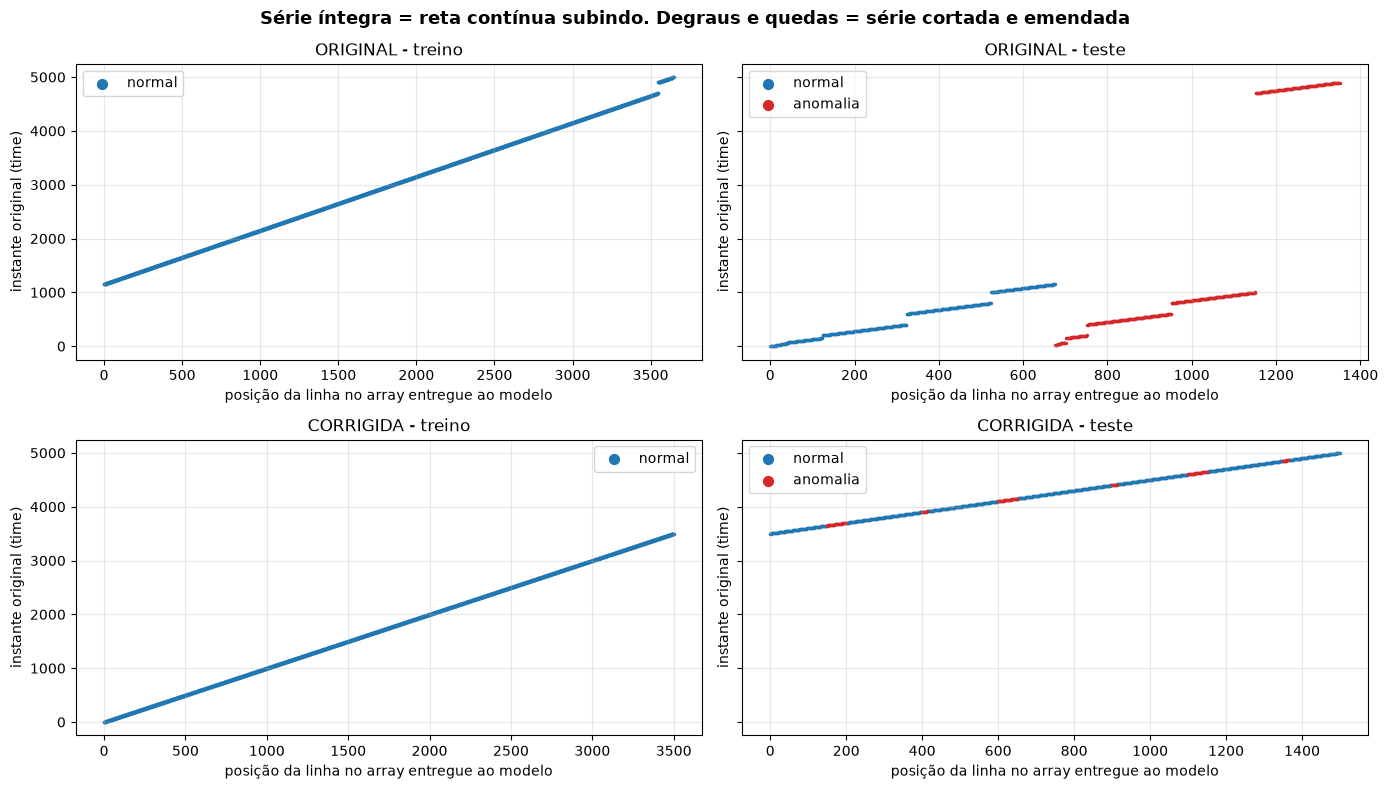

In [4]:
from examples.experimentos_desafio1 import diagnostico_ordem_temporal

diagnostico_ordem_temporal()

In [5]:
# Hypothesis set
model_ganf = GANF(
    n_blocks=6,
    input_features=1,
    hidden_size=32,
    n_hidden=1,
    model="MAF",
    device="cpu",
    time_series_amount=X_train.shape[1],
)

# Optimizer
weight_decay = 0.1
learning_rate = 1e-4
optimizer = torch.optim.Adam(
    [
        {"params": model_ganf.parameters(), "weight_decay": weight_decay},
        {"params": [model_ganf.adjacency_matrix]},
    ],
    lr=learning_rate,
    weight_decay=0.0,
)

# Error Measure
negative_log_prob_loss = ForwardLoss()
dag_loss = TraceExponentialMatrixLoss()
loss = LagrangeLoss(primal_loss=negative_log_prob_loss, dual_losses=[dag_loss])

In [6]:
# Learning algorithm
learning_algorithm = LagrangeTrainer()

learning_algorithm.fit(    
    model=model_ganf,
    optimizer=optimizer,
    loss=loss,
    train_loader = training_samples,
    epochs=2,
    interactions=2
)

Training: 100%|██████████| 4/4 [01:55<00:00, 28.80s/epoch, loss=-10.348169326782227]


GANF(
  (rnn): LSTM(1, 32, batch_first=True)
  (gcn): GNN(
    (lin_n): Linear(in_features=32, out_features=32, bias=True)
    (lin_r): Linear(in_features=32, out_features=32, bias=False)
    (lin_2): Linear(in_features=32, out_features=32, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (nf): MAF(
    (net): FlowSequential(
      (0): MADE(
        (net_input): MaskedLinear(in_features=1, out_features=32, bias=True, cond_features=32)
        (net): Sequential(
          (0): Tanh()
          (1): MaskedLinear(in_features=32, out_features=32, bias=True)
          (2): Tanh()
          (3): MaskedLinear(in_features=32, out_features=2, bias=True)
        )
      )
      (1): MADE(
        (net_input): MaskedLinear(in_features=1, out_features=32, bias=True, cond_features=32)
        (net): Sequential(
          (0): Tanh()
          (1): MaskedLinear(in_features=32, out_features=32, bias=True)
          (2): Tanh()
          (3): MaskedLinear(in_features=32, out_features=2, 

In [7]:
predict_algorithm = StandardPredictor()

y_hat, y = predict_algorithm.predict(function=model_ganf, dataloader=test_samples, pointwise=True, aggregation="mean")



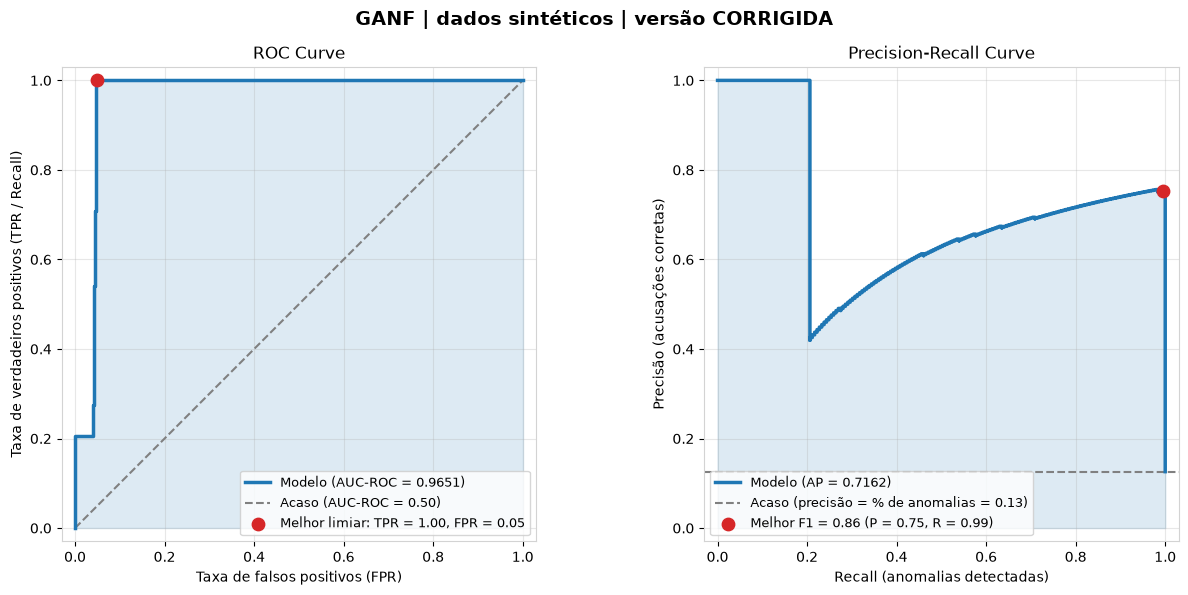

In [8]:
roc_auc, pr_auc = plot_roc_pr_curves(y, y_hat, title=f"GANF | dados sintéticos | versão {nome_versao}")


>>> GANF | A: original + anomalias originais


Training: 100%|██████████| 4/4 [00:58<00:00, 14.68s/epoch, loss=-9.788192749023438] 


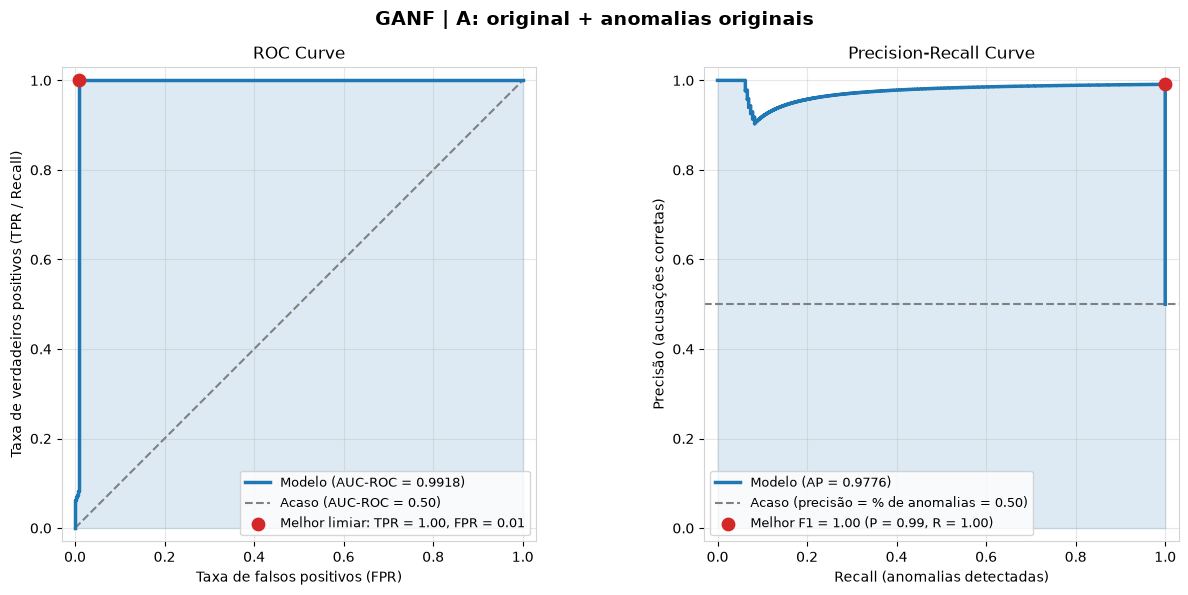


>>> GANF | B: corrigida + anomalias originais


Training: 100%|██████████| 4/4 [00:32<00:00,  8.06s/epoch, loss=-9.97467041015625]  


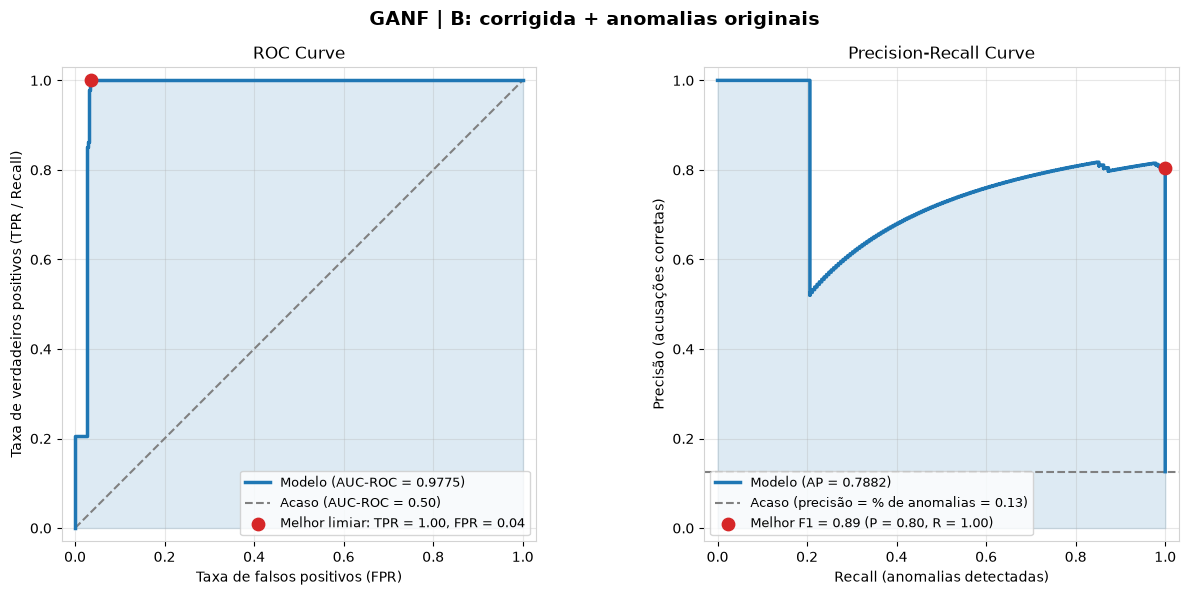


>>> GANF | C: original + anomalias de 2 desvios


Training: 100%|██████████| 4/4 [00:47<00:00, 11.83s/epoch, loss=-9.788192749023438] 


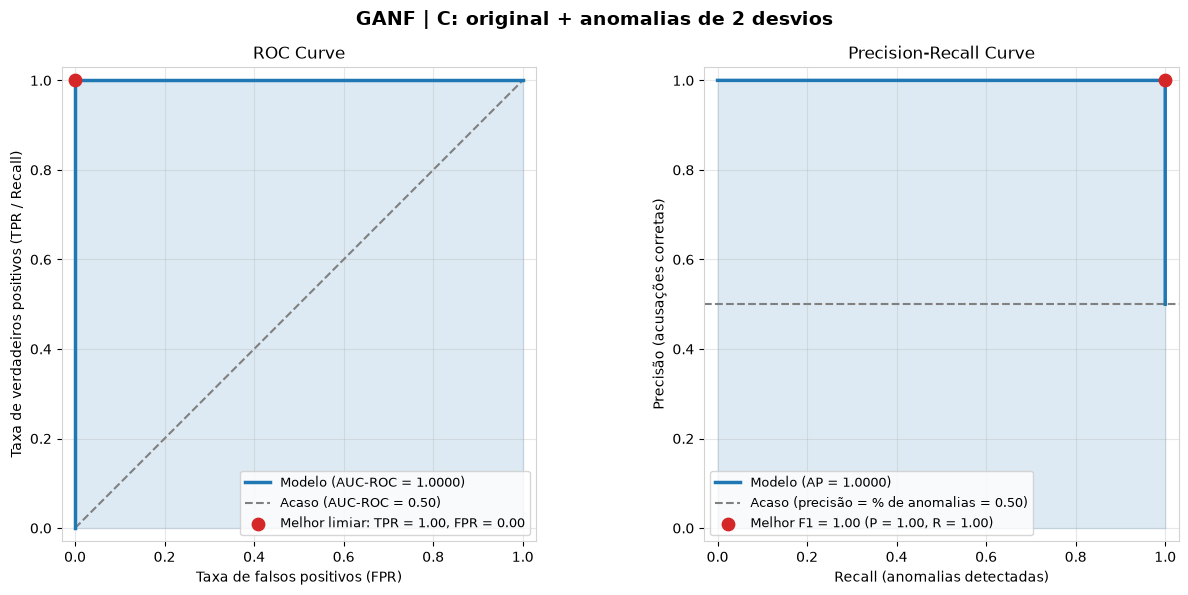


>>> GANF | D: corrigida + anomalias de 2 desvios


Training: 100%|██████████| 4/4 [00:24<00:00,  6.13s/epoch, loss=-9.97467041015625]  


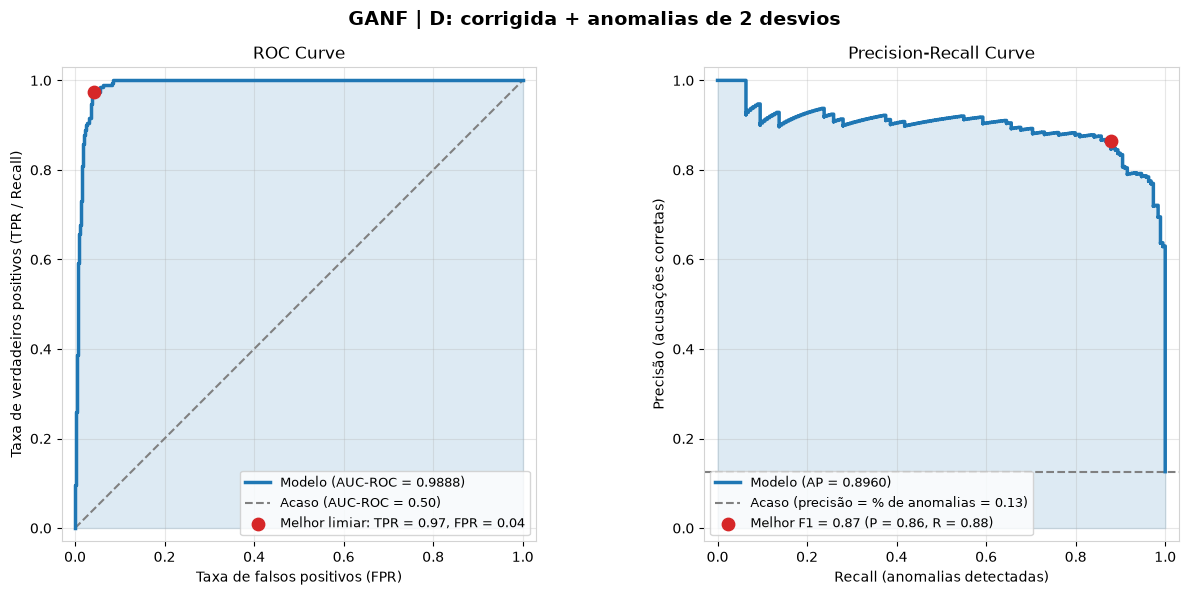

,cenário,AUC-ROC,AP,AP do acaso (% anomalias)
0,A: original + anomalias originais,0.9918,0.9776,0.500
1,B: corrigida + anomalias originais,0.9775,0.7882,0.126
2,C: original + anomalias de 2 desvios,1.0000,1.0000,0.500
3,D: corrigida + anomalias de 2 desvios,0.9888,0.8960,0.126


In [9]:
from examples.experimentos_desafio1 import rodar_cenarios_ganf, tabela_resultados, graficos_comparativos, notas_ao_longo_do_tempo

K = 2  # tamanho das anomalias nos cenários C e D, em desvios-padrão

resultados = rodar_cenarios_ganf(k=K)   # treina os 4 cenários e mostra o gráfico de cada um
tabela_resultados(resultados)

#### Acoustic Data

In [12]:
X_train, y_train, X_test, y_test = get_acoustic_sample_data()


preprocessing_steps = nn.Sequential(
    Wav2Array(sampling_rate=16000),
    Array2Mfcc(sampling_rate=16000),
)

X_train = preprocessing_steps(X_train)
X_test = preprocessing_steps(X_test)

X_train = torch.permute(X_train,(0,2,1))
X_test = torch.permute(X_test,(0,2,1))

training_samples = get_dataloader(
    X_train,
    y_train,
    window_size=12,
    stride_size=1,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    persistent_workers=False,
    drop_last=False,
)

test_samples = get_dataloader(
    X_test,
    y_test,
    window_size=12,
    stride_size=1,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    persistent_workers=False,
    drop_last=False,
)

c:\Users\tacio\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [13]:
X_train.shape

torch.Size([5, 313, 20])

In [14]:
# Hypothesis set
model_ganf = GANF(
    n_blocks=6,
    input_features=1,
    hidden_size=32,
    n_hidden=1,
    model="MAF",
    device="cpu",
    time_series_amount=X_train.shape[2],
)

# Optimizer
weight_decay = 0.1
learning_rate = 1e-4
optimizer = torch.optim.Adam(
    [
        {"params": model_ganf.parameters(), "weight_decay": weight_decay},
        {"params": [model_ganf.adjacency_matrix]},
    ],
    lr=learning_rate,
    weight_decay=0.0,
)

# Error Measure
negative_log_prob_loss = ForwardLoss()
dag_loss = TraceExponentialMatrixLoss()
loss = LagrangeLoss(primal_loss=negative_log_prob_loss, dual_losses=[dag_loss])

In [15]:
# Learning algorithm
learning_algorithm = LagrangeTrainer()

learning_algorithm.fit(    
    model=model_ganf,
    optimizer=optimizer,
    loss=loss,
    train_loader = training_samples,
    epochs=2,
    interactions=2
)

Training: 100%|██████████| 4/4 [00:34<00:00,  8.70s/epoch, loss=568.45361328125]


GANF(
  (rnn): LSTM(1, 32, batch_first=True)
  (gcn): GNN(
    (lin_n): Linear(in_features=32, out_features=32, bias=True)
    (lin_r): Linear(in_features=32, out_features=32, bias=False)
    (lin_2): Linear(in_features=32, out_features=32, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (nf): MAF(
    (net): FlowSequential(
      (0): MADE(
        (net_input): MaskedLinear(in_features=1, out_features=32, bias=True, cond_features=32)
        (net): Sequential(
          (0): Tanh()
          (1): MaskedLinear(in_features=32, out_features=32, bias=True)
          (2): Tanh()
          (3): MaskedLinear(in_features=32, out_features=2, bias=True)
        )
      )
      (1): MADE(
        (net_input): MaskedLinear(in_features=1, out_features=32, bias=True, cond_features=32)
        (net): Sequential(
          (0): Tanh()
          (1): MaskedLinear(in_features=32, out_features=32, bias=True)
          (2): Tanh()
          (3): MaskedLinear(in_features=32, out_features=2, 

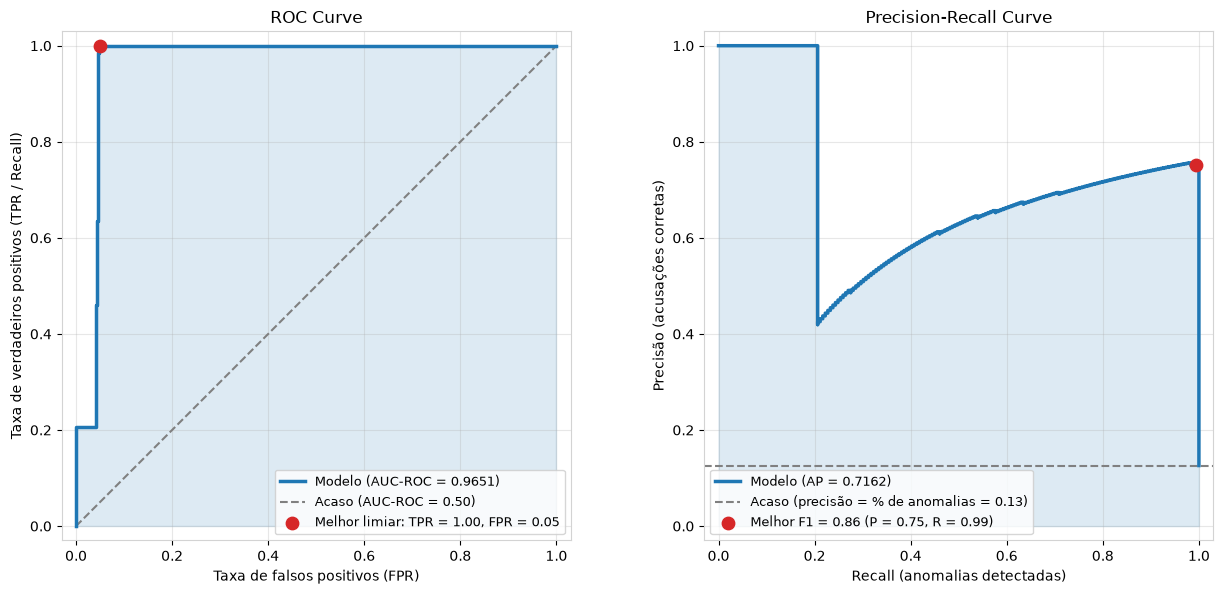

In [16]:
roc_auc, pr_auc = plot_roc_pr_curves(y, y_hat)

### Hitachi Model

#### Synthetic Data

In [17]:
from sklearn.preprocessing import StandardScaler

from mtsa.losses.mse_loss import MSELoss
from mtsa.models.hitachi import ReconstructionError, WindowedHitachi
from mtsa.trainers.unsupervised_trainer import UnsupervisedTrainer

print("Usando a versão", nome_versao)   # mesma escolha feita no seletor do Desafio 1
X_train, y_train, X_test, y_test = get_tabular_sample_data()

# Padronização com média e desvio do TREINO (o teste não é usado para isso)
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

training_samples = get_dataloader(
    X_train,
    y_train,
    window_size=12,
    stride_size=1,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    persistent_workers=False,
    drop_last=False,
)

test_samples = get_dataloader(
    X_test,
    y_test,
    window_size=12,
    stride_size=1,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    persistent_workers=False,
    drop_last=False,
)

Usando a versão CORRIGIDA
Test normals : 1311
Test anomalies: 189
Train normals : 3500
Train anomalies: 0


In [18]:
# Hypothesis set
model_hitachi = WindowedHitachi(window_size=12, n_features=X_train.shape[1])

# Optimizer
learning_rate = 1e-3
optimizer = torch.optim.Adam(model_hitachi.parameters(), lr=learning_rate)

# Error Measure
loss = MSELoss()

In [19]:
# Learning algorithm
learning_algorithm = UnsupervisedTrainer()

learning_algorithm.fit(
    model=model_hitachi,
    optimizer=optimizer,
    loss=loss,
    train_loader=training_samples,
    epochs=30,
)

Training | 30 Epochs: 100%|██████████| 30/30 [00:43<00:00,  1.44s/epoch, loss=0.7771]


WindowedHitachi(
  (autoencoder): Hitachi(
    (encoder): Sequential(
      (0): Linear(in_features=72, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=8, bias=True)
      (5): ReLU()
    )
    (decoder): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): ReLU()
      (4): Linear(in_features=64, out_features=72, bias=True)
    )
  )
)

In [20]:
model_hitachi.eval()
predict_algorithm = StandardPredictor()

y_hat, y = predict_algorithm.predict(
    function=ReconstructionError(model_hitachi),
    dataloader=test_samples,
    pointwise=True,
    aggregation="mean",
    device="cpu",
)

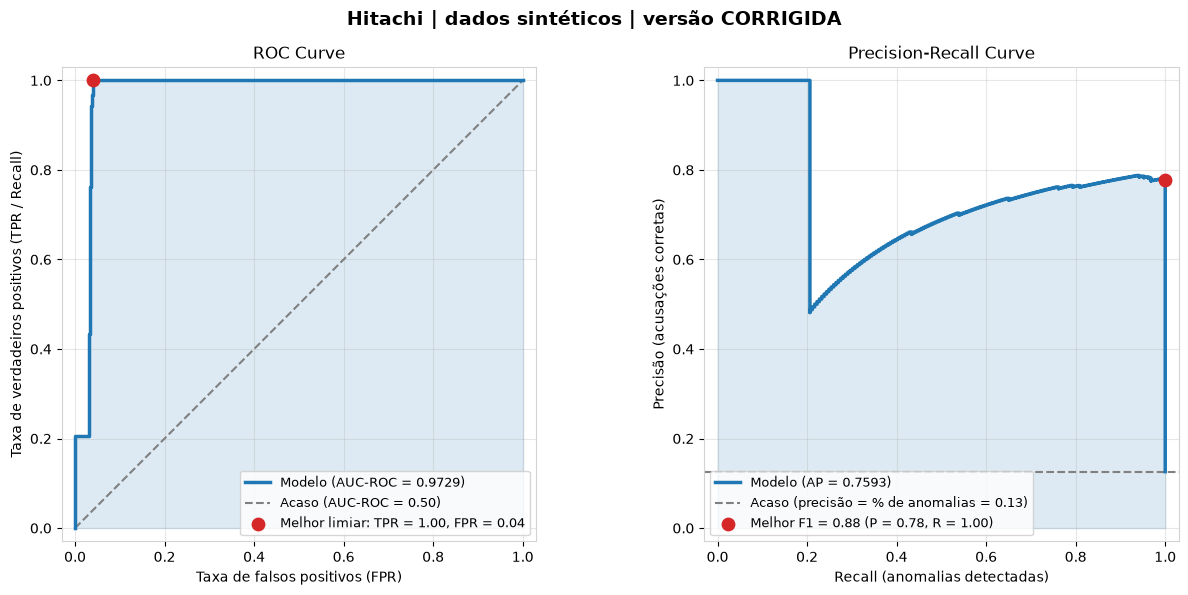

In [21]:
roc_auc, pr_auc = plot_roc_pr_curves(y, y_hat, title=f"Hitachi | dados sintéticos | versão {nome_versao}")

##### Comparação dos cenários A, B, C e D (Hitachi)

Os mesmos quatro cenários usados com o GANF, agora com o Hitachi. A e B usam os arquivos de verdade; C e D usam anomalias de **k desvios-padrão**.

| | Divisão | Anomalias |
|---|---|---|
| A | original | originais |
| B | corrigida | originais |
| C | original | k desvios |
| D | corrigida | k desvios |


>>> Hitachi | A: original + anomalias originais


Training | 30 Epochs: 100%|██████████| 30/30 [01:14<00:00,  2.48s/epoch, loss=0.7850]


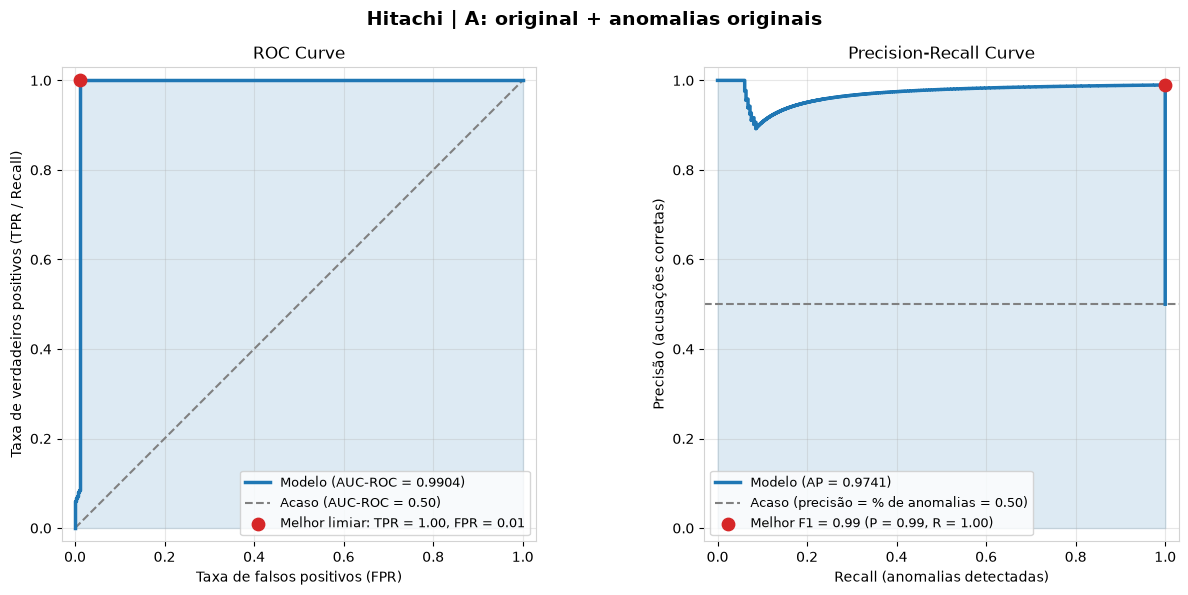


>>> Hitachi | B: corrigida + anomalias originais


Training | 30 Epochs: 100%|██████████| 30/30 [01:59<00:00,  3.98s/epoch, loss=0.7987]


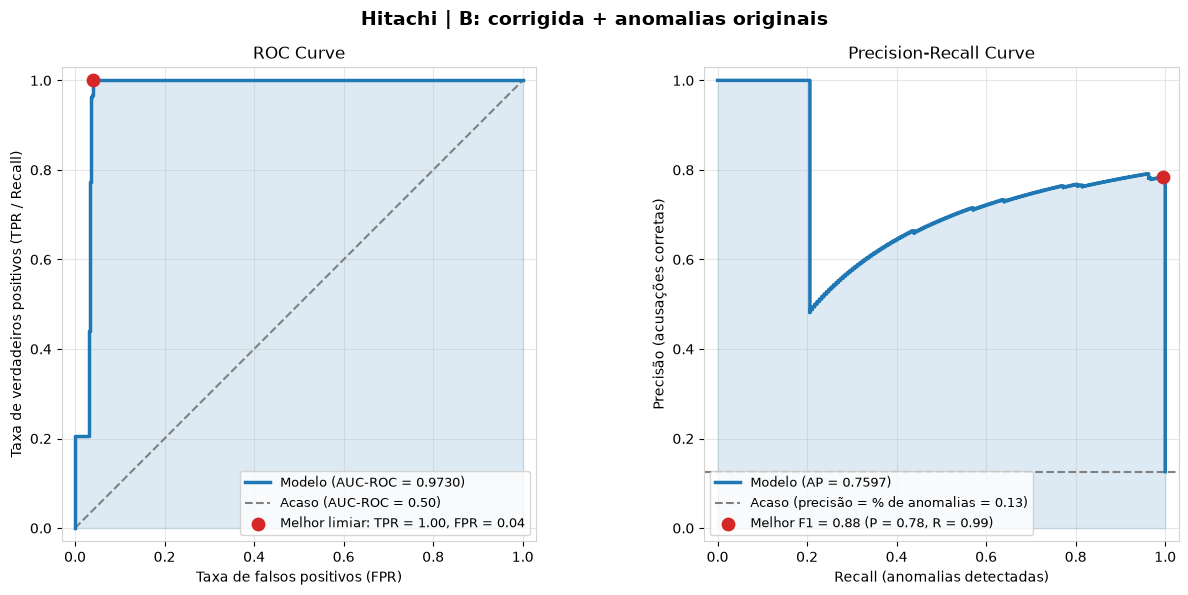


>>> Hitachi | C: original + anomalias de 2 desvios


Training | 30 Epochs: 100%|██████████| 30/30 [01:46<00:00,  3.56s/epoch, loss=0.7850]


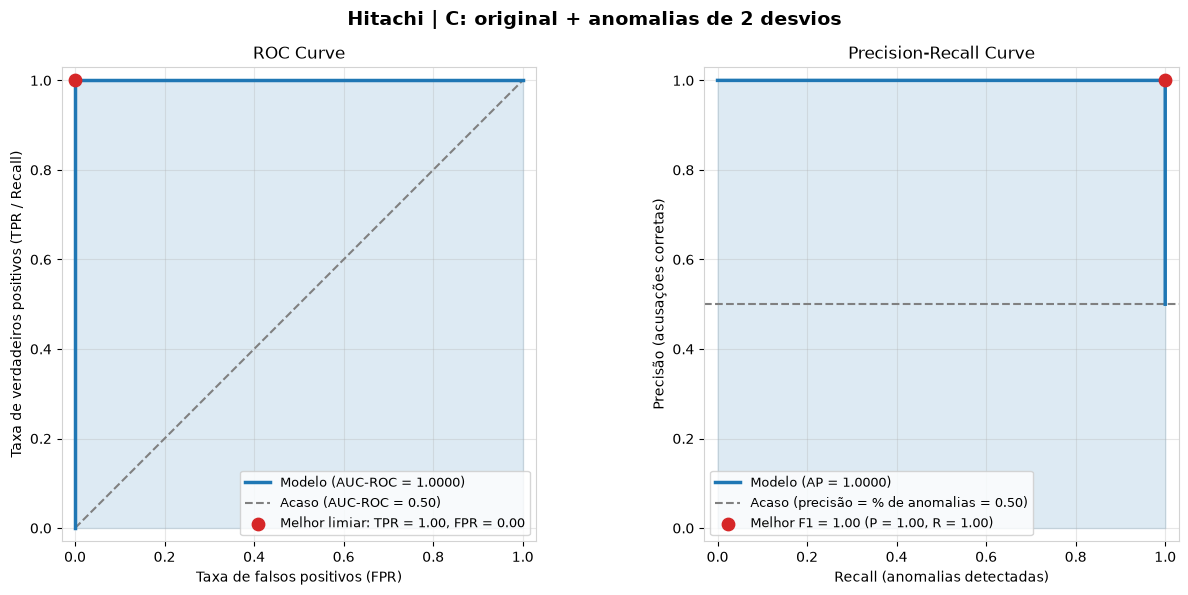


>>> Hitachi | D: corrigida + anomalias de 2 desvios


Training | 30 Epochs: 100%|██████████| 30/30 [01:27<00:00,  2.91s/epoch, loss=0.7987]


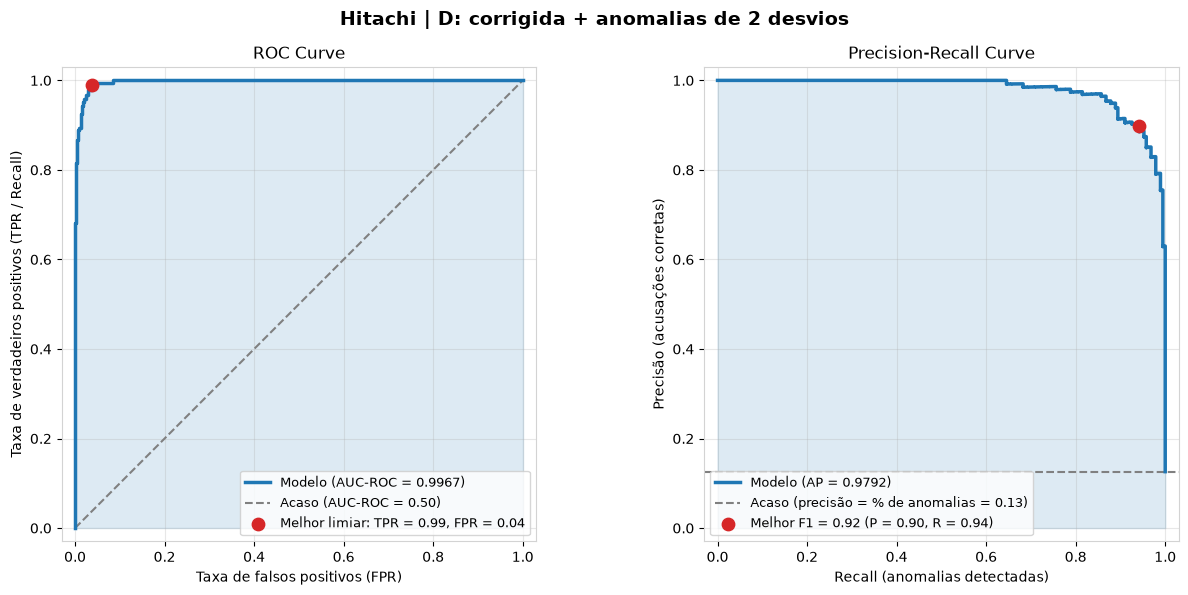

,cenário,AUC-ROC,AP,AP do acaso (% anomalias)
0,A: original + anomalias originais,0.9904,0.9741,0.500
1,B: corrigida + anomalias originais,0.9730,0.7597,0.126
2,C: original + anomalias de 2 desvios,1.0000,1.0000,0.500
3,D: corrigida + anomalias de 2 desvios,0.9967,0.9792,0.126


In [22]:
from examples.experimentos_desafio1 import rodar_cenarios_hitachi, tabela_resultados, graficos_comparativos, notas_ao_longo_do_tempo

K = 2  # tamanho das anomalias nos cenários C e D, em desvios-padrão

resultados_hitachi = rodar_cenarios_hitachi(k=K)   # treina os 4 cenários e mostra o gráfico de cada um
tabela_resultados(resultados_hitachi)

##### GANF × Hitachi

Lado a lado, os resultados dos dois modelos nos quatro cenários (é preciso ter rodado também a comparação do GANF, que cria `resultados`). Nos cenários A e B as anomalias são grandes demais e os dois tendem a empatar perto de 1; a diferença entre os modelos aparece nos cenários com anomalias realistas (C e D).

In [25]:
from examples.experimentos_desafio1 import comparar_modelos

comparar_modelos({"GANF": resultados, "Hitachi": resultados_hitachi})

AUC-ROC              AP        
modelo                                   GANF Hitachi    GANF Hitachi
cenário                                                              
A: original + anomalias originais      0.9918  0.9904  0.9776  0.9741
B: corrigida + anomalias originais     0.9775  0.9730  0.7882  0.7597
C: original + anomalias de 2 desvios   1.0000  1.0000  1.0000  1.0000
D: corrigida + anomalias de 2 desvios  0.9888  0.9967  0.8960  0.9792